In [1]:
import matplotlib.pyplot as plt

import torch
import torch.optim as optim
import torch.nn as nn
from torchvision import datasets, transforms
import imageio
from torch.utils.data import random_split

Problem 1A

In [2]:
data_path = '../ecgr4181_HW7/data'

cifar10 = datasets.CIFAR10(root=data_path, train=True, download=True)

n_cifar10  = datasets.CIFAR10(data_path, train=True, download=True, transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),(0.2470, 0.2435, 0.2616))
]))

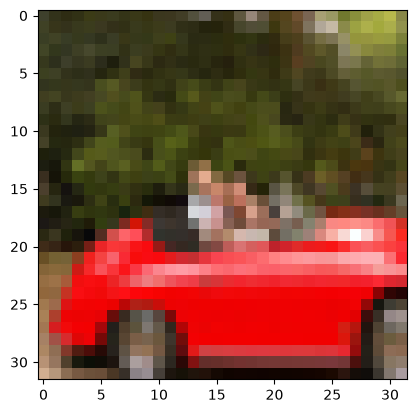

In [3]:
plt.imshow(cifar10[99][0])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9802876..2.1264887].


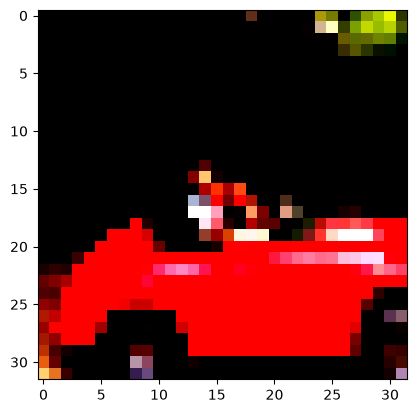

In [4]:
plt.imshow(n_cifar10[99][0].permute(1, 2, 0))

In [5]:
loss_fn = nn.CrossEntropyLoss()

def train_test(model, optimizer, epochs, cifar10):
    train_set, val_set = random_split(cifar10, [int(len(cifar10)*0.8), len(cifar10) - int(len(cifar10)*0.8)])

    train_loader = torch.utils.data.DataLoader(train_set, batch_size=256, shuffle=True)
    c_correct = 0
    c_total = 0

    v_correct = 0
    v_total = 0

    val_loader = torch.utils.data.DataLoader(val_set, batch_size=256, shuffle=False)

    train_loss = []
    val_loss = []

    for epoch in range(epochs):
        for imgs, labels in train_loader:
            imgs = imgs.to("mps")
            labels = labels.to("mps")
            batch_size = imgs.shape[0]
            outputs = model(imgs.flatten(1))
            loss =loss_fn(outputs, labels)

            _, predicted = torch.max(outputs, dim=1)
            c_total += labels.shape[0]
            c_correct += int((predicted == labels).sum())

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        if epoch % 10 == 9 or epoch == 0:
            with torch.no_grad():
                for imgs, labels in val_loader:
                    imgs = imgs.to("mps")
                    labels = labels.to("mps")
                    outputs = model(imgs.flatten(1))
                    _, predicted = torch.max(outputs, dim=1)
                    v_total += labels.shape[0]
                    v_correct += int((predicted == labels).sum())
            train_loss.append(c_correct / c_total)
            val_loss.append(v_correct / v_total)
            print(f"Training Epoch {epoch+1}, Loss: {loss.item()}")
            #print(f"Training Accuracy: {c_correct / c_total:.2f}")
            #print(f"Validation Accuracy: {v_correct / v_total:.2f}")
    plt.plot(train_loss, label='Training Accuracy')
    plt.plot(val_loss, label='Validation Accuracy')
    plt.xlabel('Epochs (x10)')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy over Epochs')
    plt.legend()
    return train_loss, val_loss

Training Epoch 1, Loss: 1.410725712776184
Training Epoch 10, Loss: 0.7351125478744507
Training Epoch 20, Loss: 0.3328419029712677
Training Epoch 30, Loss: 0.18170300126075745
Training Epoch 40, Loss: 0.10282480716705322
Training Epoch 50, Loss: 0.19066432118415833
Training Epoch 60, Loss: 0.0797625482082367
Training Epoch 70, Loss: 0.047485921531915665
Training Epoch 80, Loss: 0.04760562628507614
Training Epoch 90, Loss: 0.027912795543670654
Training Epoch 100, Loss: 0.023111991584300995


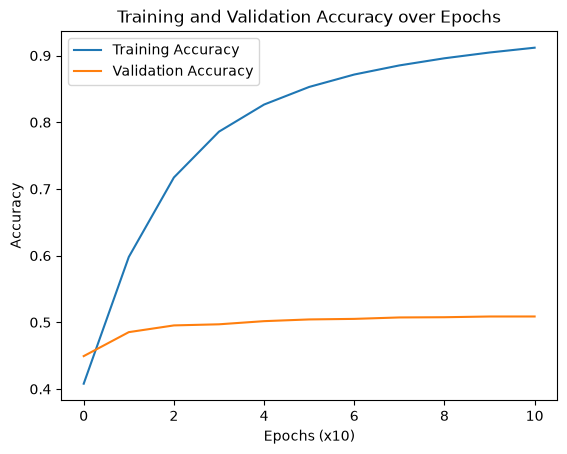

In [6]:
p1a_model = (nn.Sequential(nn.Linear(3072, 1024),
                      nn.ReLU(),
                      nn.Linear(1024, 256),
                      nn.ReLU(),
                      nn.Linear(256, 10))).to("mps")


p1a_optimizer = optim.Adam(p1a_model.parameters(), lr = 0.001)

p1a_train_loss, p1a_val_loss = train_test(p1a_model, p1a_optimizer, 100, n_cifar10)


In [7]:
numel_list = [p.numel() for p in p1a_model.parameters()]
sum(numel_list), numel_list

(3411722, [3145728, 1024, 262144, 256, 2560, 10])

Problem 1B

Training Epoch 1, Loss: 1.607792854309082
Training Epoch 10, Loss: 0.6664758920669556
Training Epoch 20, Loss: 0.35683223605155945
Training Epoch 30, Loss: 0.2520008683204651
Training Epoch 40, Loss: 0.16837723553180695
Training Epoch 50, Loss: 0.31724733114242554
Training Epoch 60, Loss: 0.1395447999238968
Training Epoch 70, Loss: 0.043511416763067245
Training Epoch 80, Loss: 0.06719465553760529
Training Epoch 90, Loss: 0.030907824635505676
Training Epoch 100, Loss: 0.0701238363981247


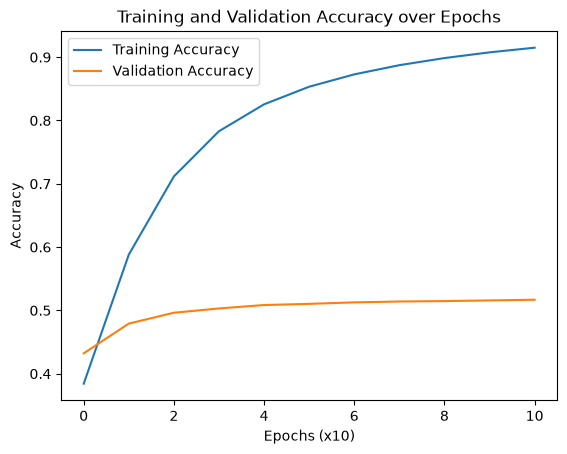

In [8]:
p1b_model = (nn.Sequential(nn.Linear(3072, 1024),
                      nn.ReLU(),
                      nn.Linear(1024, 341),
                      nn.ReLU(),
                      nn.Linear(341, 113),
                      nn.ReLU(),
                      nn.Linear(113, 38),
                      nn.ReLU(),
                      nn.Linear(38, 10))).to("mps")


p1b_optimizer = optim.Adam(p1b_model.parameters(), lr = 0.001)

p1b_train_loss, p1b_val_loss = train_test(p1b_model, p1b_optimizer, 100, n_cifar10)

In [9]:
numel_list = [p.numel() for p in p1b_model.parameters()]
sum(numel_list), numel_list

(3539645, [3145728, 1024, 349184, 341, 38533, 113, 4294, 38, 380, 10])

Problem 2A

Training Epoch 1, Loss: 2.055283784866333
Training Epoch 10, Loss: 0.7907987833023071
Training Epoch 20, Loss: 0.36819639801979065
Training Epoch 30, Loss: 0.16205157339572906
Training Epoch 40, Loss: 0.05405493825674057
Training Epoch 50, Loss: 0.21811909973621368
Training Epoch 60, Loss: 0.06262354552745819
Training Epoch 70, Loss: 0.20147648453712463
Training Epoch 80, Loss: 0.008038157597184181
Training Epoch 90, Loss: 0.009201908484101295
Training Epoch 100, Loss: 0.0051351143047213554


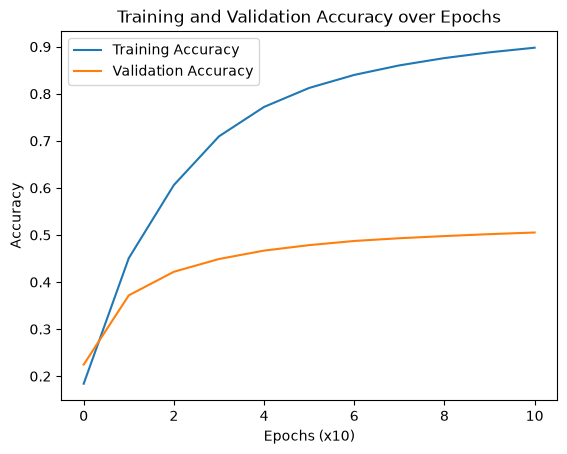

In [ ]:
p2a_model = (nn.Sequential(nn.Linear(3072, 1920),
                      nn.ReLU(),
                      nn.Linear(1920, 1200),
                      nn.ReLU(),
                      nn.Linear(1200, 750),
                      nn.ReLU(),
                      nn.Linear(750, 341),
                      nn.ReLU(),
                      nn.Linear(341, 292),
                      nn.ReLU(),
                      nn.Linear(292, 183),
                      nn.ReLU(),
                      nn.Linear(183, 113),
                      nn.ReLU(),
                      nn.Linear(113, 71),
                      nn.ReLU(),
                      nn.Linear(71, 45),
                      nn.ReLU(),
                      nn.Linear(45, 38),
                      nn.ReLU(),
                      nn.Linear(38, 10))).to("mps")


p2a_optimizer = optim.Adam(p2a_model.parameters(), lr = 0.01)

p2a_train_loss, p2a_val_loss = train_test(p2a_model, p2a_optimizer, 100, n_cifar10)

In [11]:
numel_list = [p.numel() for p in p2a_model.parameters()]
sum(numel_list), numel_list

(9549948,
 [5898240,
  1920,
  2304000,
  1200,
  900000,
  750,
  255750,
  341,
  99572,
  292,
  53436,
  183,
  20679,
  113,
  8023,
  71,
  3195,
  45,
  1710,
  38,
  380,
  10])

Problem 2B

Training Epoch 1, Loss: 1.6249027252197266
Training Epoch 10, Loss: 0.8026546835899353
Training Epoch 20, Loss: 0.44790536165237427
Training Epoch 30, Loss: 0.19418498873710632
Training Epoch 40, Loss: 0.27348554134368896
Training Epoch 50, Loss: 0.16973893344402313
Training Epoch 60, Loss: 0.0936976969242096
Training Epoch 70, Loss: 0.1620618999004364
Training Epoch 80, Loss: 0.019477400928735733
Training Epoch 90, Loss: 0.04036848992109299
Training Epoch 100, Loss: 0.22055114805698395


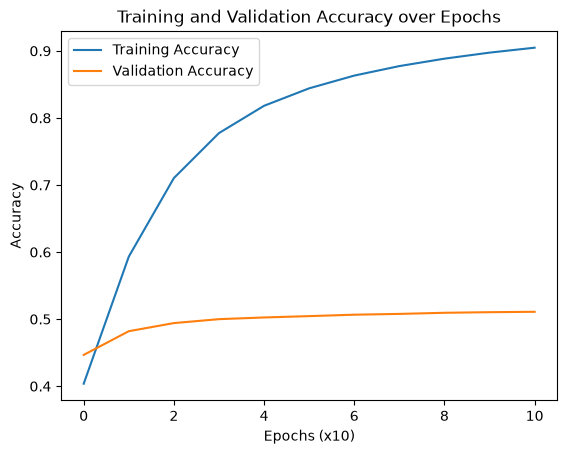

In [12]:
p2b1_model = (nn.Sequential(nn.Linear(3072, 2048),
                      nn.ReLU(),
                      nn.Linear(2048, 512),
                      nn.ReLU(),
                      nn.Linear(512, 10))).to("mps")


p2b1_optimizer = optim.Adam(p2b1_model.parameters(), lr = 0.001)

p2b1_train_loss, p2b1_val_loss = train_test(p2b1_model, p2b1_optimizer, 100, n_cifar10)

In [18]:
numel_list = [p.numel() for p in p2b1_model.parameters()]
sum(numel_list), numel_list

(7347722, [6291456, 2048, 1048576, 512, 5120, 10])

Training Epoch 1, Loss: 1.557274341583252
Training Epoch 10, Loss: 0.9564840793609619
Training Epoch 20, Loss: 0.5779210329055786
Training Epoch 30, Loss: 0.23260454833507538
Training Epoch 40, Loss: 0.13385199010372162
Training Epoch 50, Loss: 0.07569371163845062
Training Epoch 60, Loss: 0.058465972542762756
Training Epoch 70, Loss: 0.08874879777431488
Training Epoch 80, Loss: 0.020046666264533997
Training Epoch 90, Loss: 0.06339086592197418
Training Epoch 100, Loss: 0.13246600329875946


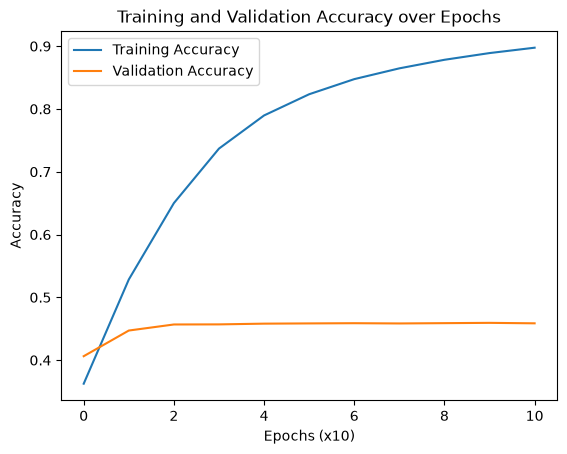

In [13]:
p2b2_model = (nn.Sequential(nn.Linear(3072, 1024),
                      nn.Sigmoid(),
                      nn.Linear(1024, 256),
                      nn.Sigmoid(),
                      nn.Linear(256, 10))).to("mps")


p2b2_optimizer = optim.Adam(p2b2_model.parameters(), lr = 0.001)

p2b2_train_loss, p2b2_val_loss = train_test(p2b2_model, p2b2_optimizer, 100, n_cifar10)

In [20]:
numel_list = [p.numel() for p in p2b2_model.parameters()]
sum(numel_list), numel_list

(3411722, [3145728, 1024, 262144, 256, 2560, 10])

Training Epoch 1, Loss: 1.739656925201416
Training Epoch 10, Loss: 1.1152307987213135
Training Epoch 20, Loss: 1.021237850189209
Training Epoch 30, Loss: 0.5844261646270752
Training Epoch 40, Loss: 0.3686821460723877
Training Epoch 50, Loss: 0.16958793997764587
Training Epoch 60, Loss: 0.4205682873725891
Training Epoch 70, Loss: 0.17864108085632324
Training Epoch 80, Loss: 0.1925525963306427
Training Epoch 90, Loss: 0.30655327439308167
Training Epoch 100, Loss: 0.2911966145038605


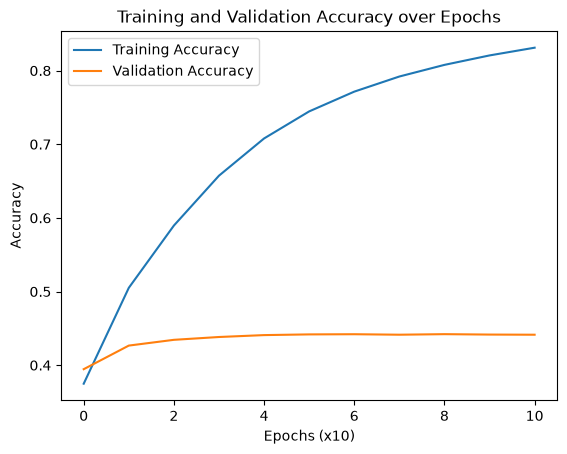

In [14]:
p2b3_model = (nn.Sequential(nn.Linear(3072, 1024),
                      nn.Tanh(),
                      nn.Linear(1024, 256),
                      nn.Tanh(),
                      nn.Linear(256, 10))).to("mps")


p2b3_optimizer = optim.Adam(p2b3_model.parameters(), lr = 0.001)

p2b3_train_loss, p2b3_val_loss = train_test(p2b3_model, p2b3_optimizer, 100, n_cifar10)

In [21]:
numel_list = [p.numel() for p in p2b3_model.parameters()]
sum(numel_list), numel_list

(3411722, [3145728, 1024, 262144, 256, 2560, 10])

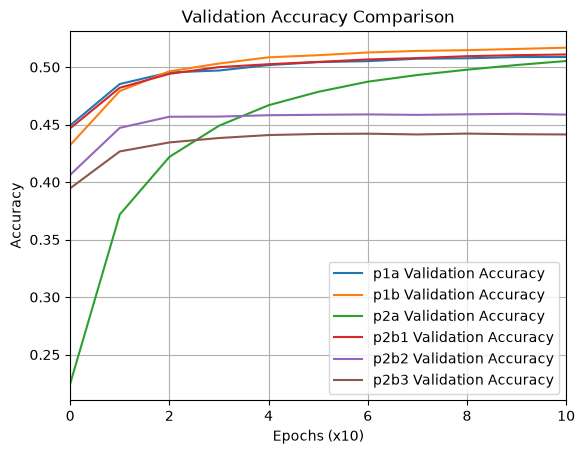

In [25]:
plt.grid()
plt.plot(p1a_val_loss, label='p1a Validation Accuracy')
plt.plot(p1b_val_loss, label='p1b Validation Accuracy')
plt.plot(p2a_val_loss, label='p2a Validation Accuracy')
plt.plot(p2b1_val_loss, label='p2b1 Validation Accuracy')
plt.plot(p2b2_val_loss, label='p2b2 Validation Accuracy')
plt.plot(p2b3_val_loss, label='p2b3 Validation Accuracy')
plt.xlim(0, 10)
plt.xlabel('Epochs (x10)')
plt.ylabel('Accuracy')
plt.title('Validation Accuracy Comparison')
plt.legend()

In [17]:
print("p1a_train_Accuracy:", p1a_train_loss[-1])
print("p1a_val_Accuracy:", p1a_val_loss[-1])
print("p1b_train_Accuracy:", p1b_train_loss[-1])
print("p1b_val_Accuracy:", p1b_val_loss[-1])
print("p2a_train_Accuracy:", p2a_train_loss[-1])
print("p2a_val_Accuracy:", p2a_val_loss[-1])
print("p2b1_train_Accuracy:", p2b1_train_loss[-1])
print("p2b1_val_Accuracy:", p2b1_val_loss[-1])
print("p2b2_train_Accuracy:", p2b2_train_loss[-1])
print("p2b2_val_Accuracy:", p2b2_val_loss[-1])
print("p2b3_train_Accuracy:", p2b3_train_loss[-1])
print("p2b3_val_Accuracy:", p2b3_val_loss[-1])


p1a_train_Accuracy: 0.91182775
p1a_val_Accuracy: 0.5087181818181818
p1b_train_Accuracy: 0.91496575
p1b_val_Accuracy: 0.5168363636363636
p2a_train_Accuracy: 0.8979065
p2a_val_Accuracy: 0.5052636363636364
p2b1_train_Accuracy: 0.9047175
p2b1_val_Accuracy: 0.5109272727272727
p2b2_train_Accuracy: 0.89754275
p2b2_val_Accuracy: 0.4586454545454545
p2b3_train_Accuracy: 0.8311135
p2b3_val_Accuracy: 0.4414
